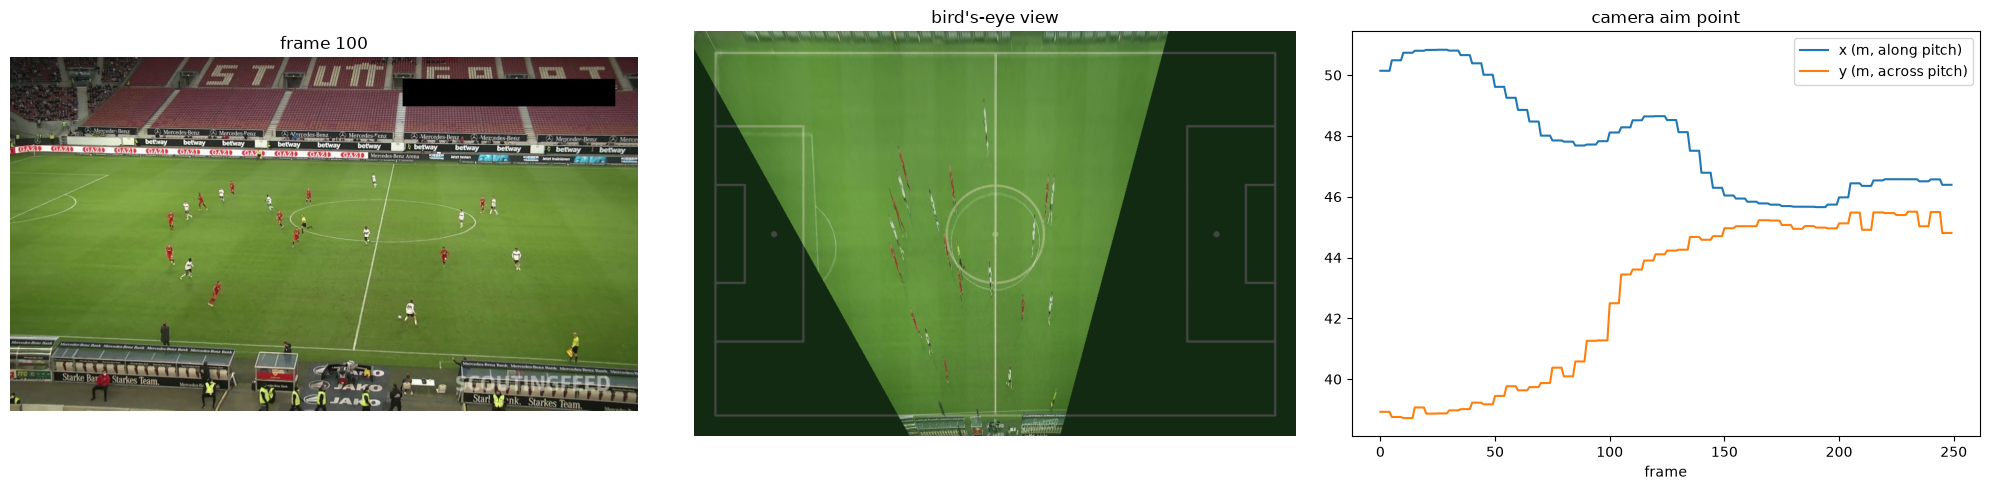

In [1]:
import cv2, numpy as np
import matplotlib.pyplot as plt
from foot_cv.pitch import PitchCanvas

H_all = np.load("outputs/stuttgart_10s/homographies.npy")   # (n_frames, 3, 3)

FRAME = 100
cap = cv2.VideoCapture("data/clips/stuttgart_10s.mp4")
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME)
_, frame = cap.read()
H = H_all[FRAME]

# Bird's-eye view: H maps pixels -> metres, S maps metres -> canvas pixels
canvas = PitchCanvas(scale=8)
S = np.array([[canvas.scale, 0, canvas.padding * canvas.scale],
              [0, canvas.scale, canvas.padding * canvas.scale],
              [0, 0, 1]])
topdown = cv2.warpPerspective(frame, S @ H, canvas.size)
overlay = cv2.addWeighted(topdown, 0.7, canvas.background, 0.3, 0)

# Camera aim point over time
centre = np.array([[[frame.shape[1] / 2, frame.shape[0] / 2]]], dtype=np.float32)
path = np.array([cv2.perspectiveTransform(centre, h)[0, 0] for h in H_all])

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
ax[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"frame {FRAME}")
ax[1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)); ax[1].set_title("bird's-eye view")
ax[2].plot(path[:, 0], label="x (m, along pitch)"); ax[2].plot(path[:, 1], label="y (m, across pitch)")
ax[2].set_xlabel("frame"); ax[2].legend(); ax[2].set_title("camera aim point")
for a in ax[:2]: a.axis("off")
plt.tight_layout(); plt.show()


In [ ]:
/Users/rodrigo/foot_cv